In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

## EDA

In [2]:
df = pd.read_csv("diversified_ecommerce_dataset.csv")
df.head()

,Product ID,Product Name,Category,Price,Discount,Tax Rate,Stock Level,Supplier ID,Customer Age Group,Customer Location,Customer Gender,Shipping Cost,Shipping Method,Return Rate,Seasonality,Popularity Index
0,P6879,Jacket,Apparel,53.85,5,15,150,S535,35-44,"New York, USA",Male,23.32,Standard,4.49,Yes,56
1,P5132,Camera,Electronics,761.26,10,15,224,S583,25-34,"London, UK",Female,20.88,Overnight,16.11,No,79
2,P2941,Sneakers,Footwear,1756.76,5,8,468,S118,25-34,"Tokyo, Japan",Non-Binary,16.43,Standard,4.93,No,40
3,P8545,Cookbooks,Books,295.24,10,15,25,S104,18-24,"Paris, France",Female,27.49,Standard,1.31,No,93
4,P4594,Camera,Electronics,832.00,10,12,340,S331,55+,"Tokyo, Japan",Male,45.93,Overnight,4.37,No,56


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 16 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   Product ID          1000000 non-null  object 
 1   Product Name        1000000 non-null  object 
 2   Category            1000000 non-null  object 
 3   Price               1000000 non-null  float64
 4   Discount            1000000 non-null  int64  
 5   Tax Rate            1000000 non-null  int64  
 6   Stock Level         1000000 non-null  int64  
 7   Supplier ID         1000000 non-null  object 
 8   Customer Age Group  1000000 non-null  object 
 9   Customer Location   1000000 non-null  object 
 10  Customer Gender     1000000 non-null  object 
 11  Shipping Cost       1000000 non-null  float64
 12  Shipping Method     1000000 non-null  object 
 13  Return Rate         1000000 non-null  float64
 14  Seasonality         1000000 non-null  object 
 15  Popularity Index

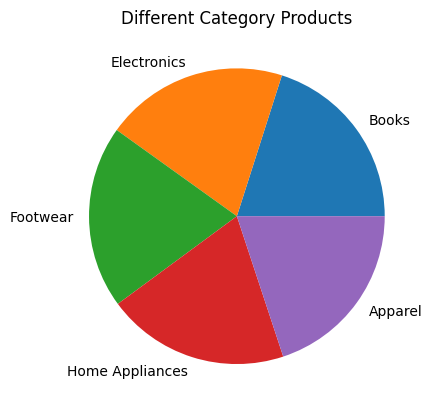

In [4]:
plt.pie(df["Category"].value_counts(),labels = df["Category"].value_counts().index)
plt.title("Different Category Products")
plt.show()

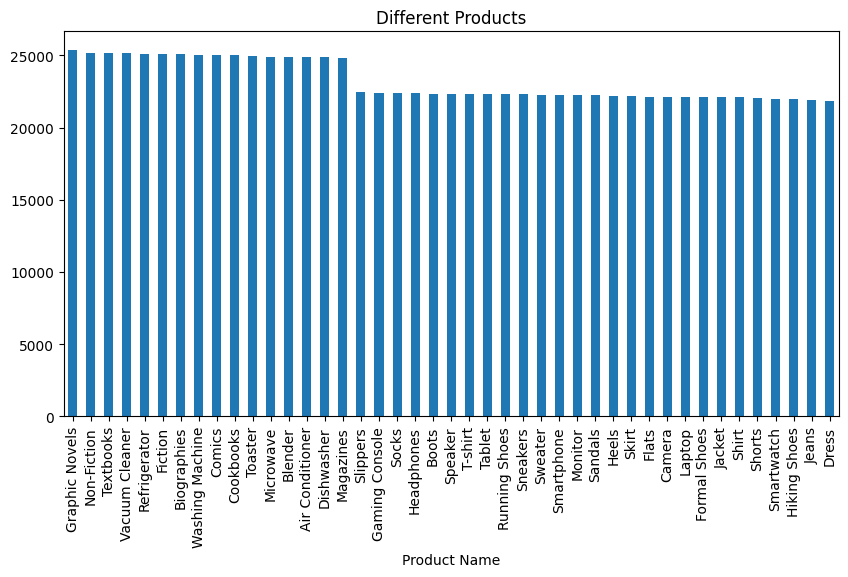

In [9]:
plt.figure(figsize=(10,5))
df["Product Name"].value_counts().plot(kind="bar")
plt.title("Different Products")
plt.show()

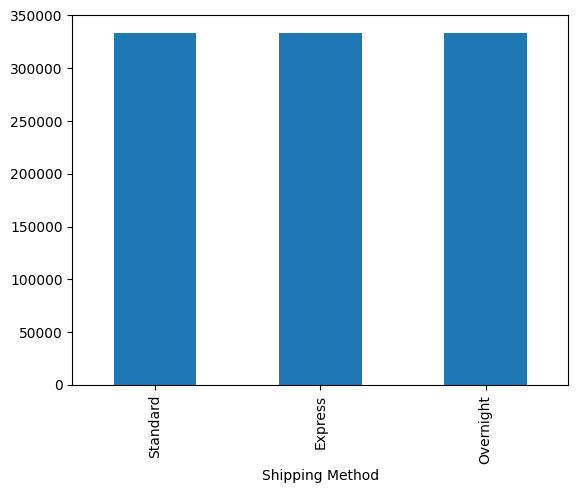

In [11]:
df["Shipping Method"].value_counts().plot(kind="bar")
plt.show()

In [13]:
df["Customer Location"].value_counts()

Customer Location
Dubai, UAE                 67253
Cape Town, South Africa    67153
Houston, USA               67048
Mumbai, India              66912
Chicago, USA               66864
Singapore                  66802
London, UK                 66715
Tokyo, Japan               66618
Phoenix, USA               66604
Toronto, Canada            66559
Los Angeles, USA           66507
New York, USA              66463
Sydney, Australia          66334
Berlin, Germany            66086
Paris, France              66082
Name: count, dtype: int64

In [14]:
# Null values
df.isnull().sum()

Product ID            0
Product Name          0
Category              0
Price                 0
Discount              0
Tax Rate              0
Stock Level           0
Supplier ID           0
Customer Age Group    0
Customer Location     0
Customer Gender       0
Shipping Cost         0
Shipping Method       0
Return Rate           0
Seasonality           0
Popularity Index      0
dtype: int64

## Preprocessing

In [16]:
X = df.drop(columns=["Product ID","Supplier ID","Popularity Index"])
y = df["Popularity Index"]

In [28]:
num_columns = X.select_dtypes(exclude=object).columns
cat_columns = X.select_dtypes(include=object).columns

In [34]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y , test_size=0.2, random_state=42)

In [18]:
numerical_transformer = Pipeline([
    ("scalar",StandardScaler())
])
categorical_transformer = Pipeline([
    ("onehot",OneHotEncoder(handle_unknown="ignore"))
])

In [30]:
preprocess = ColumnTransformer(
    transformers=[
        ("num",numerical_transformer, num_columns),
        ("cat", categorical_transformer, cat_columns)
    ]
)

# Models

## Linear Regression

In [36]:
lr_model = make_pipeline(
    preprocess,
    LinearRegression()
)

In [37]:
lr_model.fit(X_train, y_train)

,steps,"[('columntransformer', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
lr_model.score(X_train, y_train)

8.202636107346173e-05

In [40]:
y_test_pred = lr_model.predict(X_test)

print(f"Mean Squared Error: {mean_squared_error(y_test, y_test_pred)}")

Mean Squared Error: 850.3093536434245
